In [1]:
# Based on https://dev.to/pavanbelagatti/data-analysis-of-the-titanic-with-python-koj

In [2]:
%pip install --upgrade pip
%pip install matplotlib seaborn scikit-learn statsmodels

Defaulting to user installation because normal site-packages is not writeable
  Using cached pip-26.2.1-py3-none-any.whl.metadata (4.6 kB)
Using cached pip-26.2.1-py3-none-any.whl (1.8 MB)
  Attempting uninstall: pip
    Found existing installation: pip 25.3
    Uninstalling pip-25.3:
      Successfully uninstalled pip-25.3
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [3]:
from sklearn.preprocessing import OneHotEncoder, RobustScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
from sklearn import ensemble
from scipy import stats
import seaborn as sns

In [4]:
# load dataset titanic
df = sns.load_dataset("titanic")

# dimensions of your dataframe
print(df.shape)

(891, 15)


In [5]:
# only 38% survived :-(
df["survived"].value_counts(normalize=True) * 100

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [6]:
# brief description of your numerical attributes
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# count combinations of values
df.value_counts()

survived  pclass  sex     age   sibsp  parch  fare      embarked  class  who    adult_male  deck  embark_town  alive  alone
1         1       female  24.0  0      0      69.3000   C         First  woman  False       B     Cherbourg    yes    True     2
0         1       female  25.0  1      2      151.5500  S         First  woman  False       C     Southampton  no     False    1
                          50.0  0      0      28.7125   C         First  woman  False       C     Cherbourg    no     True     1
                  male    18.0  1      0      108.9000  C         First  man    True        C     Cherbourg    no     False    1
                  female  2.0   1      2      151.5500  S         First  child  False       C     Southampton  no     False    1
                                                                                                                              ..
1         3       female  4.0   1      1      16.7000   S         Third  child  False       G     Sout

In [8]:
# or counts on a single attribute
df.embark_town.value_counts()

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [9]:
# do we have null values?
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [10]:
# now some visualisations. Try different ones!

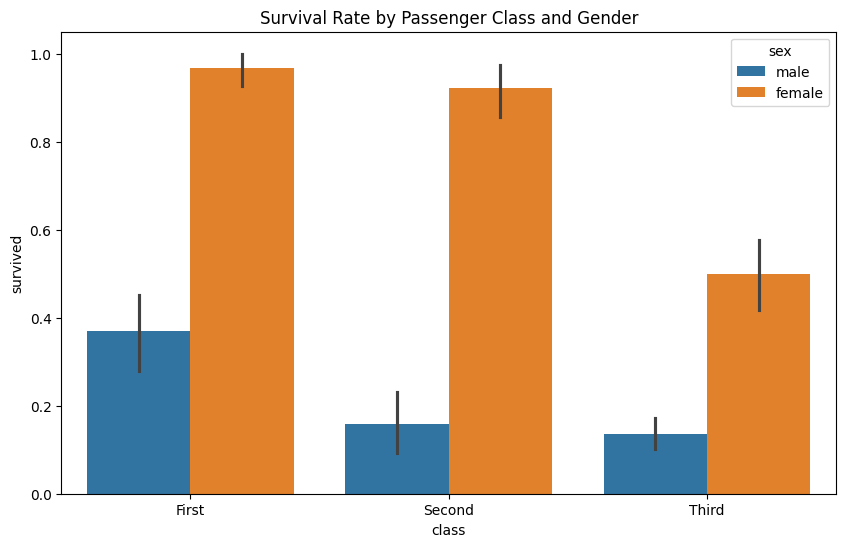

In [11]:
# histogram

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="class", y="survived", hue="sex")
plt.title("Survival Rate by Passenger Class and Gender")
plt.show()

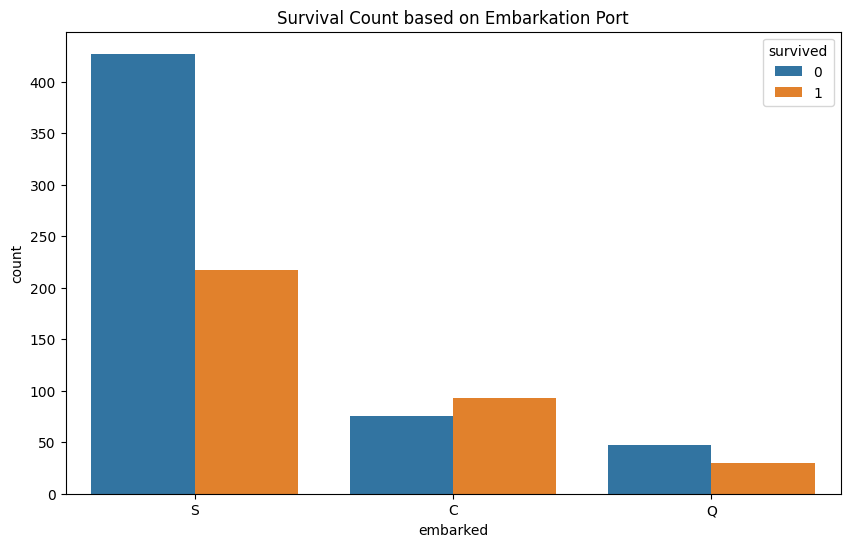

In [12]:
# plot counts

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="embarked", hue="survived")
plt.title("Survival Count based on Embarkation Port")
plt.show()

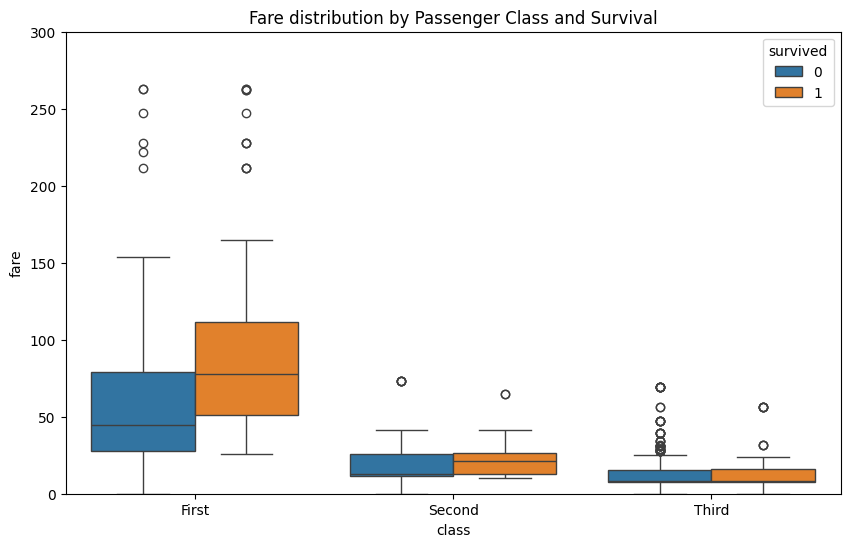

In [13]:
# perhaps your most important plot is boxplot! Take any numerical attribute and plot it along your class
# what do we see in a boxplot?

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="class", y="fare", hue="survived")
plt.ylim(0, 300)  # Limiting y-axis to 300 for better visualization
plt.title("Fare distribution by Passenger Class and Survival")
plt.show()

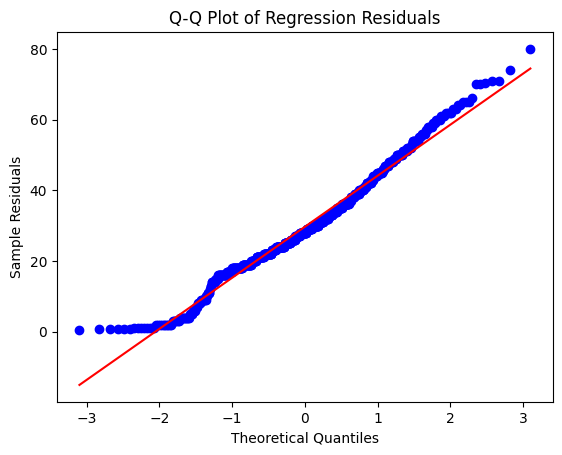

In [14]:
# Sanity check: Q-Q plot to check if errors are normally distributed

stats.probplot(df["age"].dropna(), dist="norm", plot=plt)
plt.title("Q-Q Plot of Regression Residuals")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Residuals")
plt.show()

In [15]:
# quick data aggregations using "groupby"

df.groupby("class")["age"].mean()

C:\Users\GEstrada\AppData\Local\Temp\ipykernel_26780\4195502345.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("class")["age"].mean()


class
First     38.233441
Second    29.877630
Third     25.140620
Name: age, dtype: float64

In [16]:
# data preparation for classification: check for collinearity in input data

df[["survived", "alive"]].value_counts()

# Warning: Survived and Alive are proxy of each other!!!

survived  alive
0         no       549
1         yes      342
Name: count, dtype: int64

In [17]:
# data preparation for classification (using "survived" as target variable)
X = df.drop(["survived", "alive"], axis=1)
y = df["survived"]

# Data splitting for stratified 10-fold cross-validation
cv = StratifiedKFold(10)            # for stratified 10-fold cross-validation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)    # stratified train-test split

In [18]:
# Baseline classification model (logistic regression or naive Bayes)
model = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ("scale", RobustScaler()),
    ("clf", LogisticRegression(class_weight='balanced'))
])

# It's time to calculate the test accuracy on the hold-out test set!
# Show the confusion matrix for the classifier (warning: only using one train/test split here!)
y_pred = model.fit(X_train, y_train).predict(X_test)
print("Macro Avg F1-score: %.1f" % (100*f1_score(y_test, y_pred, average="macro")))

Macro Avg F1-score: 81.5


In [19]:
# warning: evaluation based on only one train/test split, not cross-validation!
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[90 20]
 [12 57]]
              precision    recall  f1-score   support

           0       0.88      0.82      0.85       110
           1       0.74      0.83      0.78        69

    accuracy                           0.82       179
   macro avg       0.81      0.82      0.81       179
weighted avg       0.83      0.82      0.82       179



In [20]:
# now run stratified 10-fold cross-validation results for the model (warning: this is a different evaluation than the one above!)
scores = cross_val_score(model, X, y, cv=cv, n_jobs=-1, scoring="f1_macro")
print("CV training accuracy scores for each fold:", scores)
print(f"CV mean training accuracy: {scores.mean():.3f} (+/- {scores.std():.3f})")

CV training accuracy scores for each fold: [0.81481481 0.83342246 0.74858757 0.81836735 0.81496881 0.78809524
 0.83143939 0.78582888 0.83674004 0.88338574]
CV mean training accuracy: 0.816 (+/- 0.034)


In [21]:
# Now using a random forest classifier with a small number of estimators (10) to see if we can improve the results.
# We will use a pipeline to encode categorical attributes and scale numerical attributes.
pipeline = Pipeline([
    ("encode", OneHotEncoder(sparse_output=False, handle_unknown='ignore')),   # encoding categorical attributes
    ("scaler", RobustScaler()), # scaling robust to outliers
    ("classifier", ensemble.RandomForestClassifier(n_estimators=10)) # small number of estimators
])

scores = cross_val_score(pipeline, X, y, cv=cv, n_jobs=-1, scoring="f1_macro")  # f1_macro for imbalanced classes
print("Classification accuracy values using 10-fold CV:", scores)   # any negative or extreme values?
print(f"CV mean training accuracy: {scores.mean():.3f} (+/- {scores.std():.3f})")

Classification accuracy values using 10-fold CV: [0.7265883  0.80200222 0.69310345 0.83674004 0.82049213 0.75915112
 0.7954023  0.7337986  0.84030366 0.78042763]
CV mean training accuracy: 0.779 (+/- 0.047)


In [22]:
# Baseline classification model (logistic regression or naive Bayes)
model = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ("scale", MinMaxScaler()),
    ("clf", MultinomialNB())
])

# It's time to calculate the test accuracy on the hold-out test set!
# Show the confusion matrix for the classifier (warning: only using one train/test split here!)
y_pred = model.fit(X_train, y_train).predict(X_test)
print("Macro Avg F1-score: %.1f" % (100*f1_score(y_test, y_pred, average="macro")))

Macro Avg F1-score: 82.0


In [23]:
# warning: evaluation based on only one train/test split, not cross-validation!
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[91 19]
 [12 57]]
              precision    recall  f1-score   support

           0       0.88      0.83      0.85       110
           1       0.75      0.83      0.79        69

    accuracy                           0.83       179
   macro avg       0.82      0.83      0.82       179
weighted avg       0.83      0.83      0.83       179



In [ ]:
# Q: Which model performed better? Why do you think that is the case?
# Q: What are the limitations of the models used in this notebook?